In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Small worked example

In [2]:
# Pick 5 random points in the unit square
np.random.seed(42)
n = 5
points = np.random.rand(n, 2)
print("Random points in the unit square:")
print(points)

Random points in the unit square:
[[0.37454012 0.95071431]
 [0.73199394 0.59865848]
 [0.15601864 0.15599452]
 [0.05808361 0.86617615]
 [0.60111501 0.70807258]]


In [3]:
# Count how many are in the unit circle
in_circle = np.sum(points**2, axis=1) <= 1
in_circle_count = np.sum(in_circle)
print("Number of points in the unit circle:", in_circle_count)

# Estimate the value of pi using the ratio of points inside the circle to total points
pi_estimate = 4 * in_circle_count / len(points)
print("Estimated value of pi:", pi_estimate)

Number of points in the unit circle: 4
Estimated value of pi: 3.2


In [4]:
# Coordinate-wise sample variance
sample_variance = np.var(points, axis=0, ddof=1)
print("Sample variance of the points:", sample_variance)

# Pi estimate sample variance
pi_estimate_variance = np.var(4 * in_circle, ddof=1) / n
print("Sample variance of the pi estimate:", pi_estimate_variance)

# Confidence interval for the pi estimate
stderr = np.sqrt(pi_estimate_variance)
z = 1.96
ci_lower, ci_upper = pi_estimate - z * stderr, pi_estimate + z * stderr
print(f"95% CI: [{ci_lower:.4f}, {ci_upper:.4f}]")

Sample variance of the points: [0.08163114 0.0967589 ]
Sample variance of the pi estimate: 0.6400000000000002
95% CI: [1.6320, 4.7680]


In [5]:
# Approximate error of the pi estimate
approx_error = np.abs(pi_estimate - np.pi)
print("Approximate error of the pi estimate:", approx_error)

Approximate error of the pi estimate: 0.05840734641020706


## Exact values and second-way check

In [6]:
from fractions import Fraction

# Same 5 points, now with exact arithmetic: Y_i = 4 * 1(x_i^2 + y_i^2 <= 1)
Y = [Fraction(4) if Fraction(x)**2 + Fraction(y)**2 <= 1 else Fraction(0) for x, y in points]
print("Y =", [str(y) for y in Y])

# pi_hat = (1/n) sum Y_i
pi_hat = sum(Y) / n
print("pi_hat =", pi_hat)

# s^2 = 1/(n-1) sum (Y_i - pi_hat)^2, and the estimated Var(pi_hat) = s^2 / n
s2 = sum((y - pi_hat)**2 for y in Y) / (n - 1)
print("s^2 =", s2, "  s^2/n =", s2 / n)

# Second-way check: s^2 = n/(n-1) * (mean(Y^2) - pi_hat^2) must give the same value
s2_alt = Fraction(n, n - 1) * (sum(y**2 for y in Y) / n - pi_hat**2)
print("s^2 (second way) =", s2_alt, "  equal:", s2 == s2_alt)

# The float results above agree with the exact ones
print("float vs exact:", pi_estimate - float(pi_hat), pi_estimate_variance - float(s2 / n))

Y = ['0', '4', '4', '4', '4']
pi_hat = 16/5
s^2 = 16/5   s^2/n = 16/25
s^2 (second way) = 16/5   equal: True
float vs exact: 0.0 2.220446049250313e-16


# Implementation

In [7]:
def estimate_pi(n, rng):
    # Generate n random (x, y) points in the unit square
    points = rng.random((n, 2))

    # Evaluating the indicator function 1(x^2 + y^2 <= 1)
    in_circle = np.sum(points**2, axis=1) <= 1

    # Estimate pi using the ratio of points inside the circle to total points
    in_circle_count = np.sum(in_circle)
    pi_estimate = 4 * in_circle_count / n

    # Find the sample variance of the estimate
    pi_estimate_variance = np.var(4 * in_circle, ddof=1) / n

    # Find the confidence interval based on the variance
    stderr = np.sqrt(pi_estimate_variance)
    z = 1.96
    ci_lower, ci_upper = pi_estimate - z * stderr, pi_estimate + z * stderr

    return pi_estimate, (ci_lower, ci_upper)

# Test

In [8]:
rng = np.random.default_rng(42)
for n in [1e1, 1e2, 1e3, 1e4, 1e6, 1e8]:
    n = int(n)
    pi_estimate, ci = estimate_pi(n, rng)
    print(f"n = {n:,}")
    print(f"pi estimate = {pi_estimate}")
    print(f"95% CI = {ci[0]:.4f}, {ci[1]:.4f}")
    approx_error = np.abs(pi_estimate - np.pi)
    print(f"Approximate error = {approx_error}")
    print()

n = 10
pi estimate = 2.4
95% CI = 1.1197, 3.6803
Approximate error = 0.7415926535897932

n = 100
pi estimate = 3.08
95% CI = 2.7484, 3.4116
Approximate error = 0.061592653589793045

n = 1,000
pi estimate = 3.124
95% CI = 3.0214, 3.2266
Approximate error = 0.017592653589793006

n = 10,000
pi estimate = 3.1544
95% CI = 3.1224, 3.1864
Approximate error = 0.012807346410206755

n = 1,000,000
pi estimate = 3.143088
95% CI = 3.1399, 3.1463
Approximate error = 0.001495346410206988



n = 100,000,000
pi estimate = 3.14161476
95% CI = 3.1413, 3.1419
Approximate error = 2.210641020683468e-05



# Integral estimators and comparison helper

In [9]:
def report(name, mine, ref):
    """Print max |mine - ref| and the relative error ||mine - ref|| / ||ref||."""
    mine, ref = np.asarray(mine, float), np.asarray(ref, float)
    abs_err = np.abs(mine - ref).max()
    rel_err = np.linalg.norm(mine - ref) / np.linalg.norm(ref)
    print(f"{name:32s} max|diff| = {abs_err:.2e} rel = {rel_err:.2e}")


# Sample-mean estimator: I_hat = (1/n) sum f(U_i), U_i ~ U(0,1); returns (I_hat, s)
def my_sample_mean(f, n, rng):
    Y = f(rng.random(n))
    return Y.mean(), Y.std(ddof=1)


# Hit-or-miss estimator: I_hat = (1/n) sum c * 1(V_i <= f(U_i)), U_i ~ U(0,1), V_i ~ U(0,c); returns (I_hat, s)
def my_hit_or_miss(f, c, n, rng):
    U = rng.random(n)
    V = c * rng.random(n)
    Y = c * (V <= f(U))
    return Y.mean(), Y.std(ddof=1)

This is the code given in the assignment sheet exactly. Note: not sure if we need this exact code or what it is supposed to do.

In [10]:
from scipy import integrate # check only

rng = np.random.default_rng(0)
f, n, R = np.exp, 1000, 2000
I_lib = integrate.quad(f, 0, 1)[0]

sm = np.array([my_sample_mean(f, n, rng) for _ in range(R)]) # (est, s)
hm = np.array([my_hit_or_miss(f, np.e, n, rng) for _ in range(R)])

print(I_lib, np.e - 1)
print(n * sm[:, 0].var(), (np.e**2 - 1) / 2 - (np.e - 1)**2) # Q5
print(n * hm[:, 0].var(), np.e - 1)
lo, hi = sm[:, 0] - 1.96 * sm[:, 1] / np.sqrt(n), sm[:, 0] + 1.96 * sm[:, 1] / np.sqrt(n)
print(np.mean((lo <= I_lib) & (I_lib <= hi))) # Q2-style coverage

1.7182818284590453 1.718281828459045
0.24840652964546076 0.24203560745276542
1.7007630105415892 1.718281828459045
0.9495


# Assumptions

1. We assume that NumPy provides a proper pRNG, which means each trial is independantly and identically distributed. This also means that we are assuming the distribution behaves like $U(0,1)$.

2. We assume that n is large enough for the central limit theorem to apply.

# test assumption 2?

# Simulation test

In [11]:
from scipy import stats # check only

# Truth: |pi_hat - pi| should be within 3 standard errors and shrink as n grows
# Library: the same interval from scipy.stats.sem on the same draws should agree to rounding level
for n in [50, 500, 5_000]:
    pi_estimate, ci = estimate_pi(n, np.random.default_rng(42))
    stderr = (ci[1] - ci[0]) / (2 * 1.96)
    print(f"n = {n:,}: pi estimate = {pi_estimate}, |error| = {abs(pi_estimate - np.pi):.4f}, "
          f"|error| / SE = {abs(pi_estimate - np.pi) / stderr:.2f}")

    points = np.random.default_rng(42).random((n, 2))
    Y = 4.0 * (np.sum(points**2, axis=1) <= 1)
    ci_lib = (Y.mean() - 1.96 * stats.sem(Y), Y.mean() + 1.96 * stats.sem(Y))
    report(f"CI vs scipy.stats.sem (n = {n})", ci, ci_lib)

n = 50: pi estimate = 3.28, |error| = 0.1384, |error| / SE = 0.63
CI vs scipy.stats.sem (n = 50)   max|diff| = 0.00e+00 rel = 0.00e+00
n = 500: pi estimate = 3.096, |error| = 0.0456, |error| / SE = 0.61
CI vs scipy.stats.sem (n = 500)  max|diff| = 0.00e+00 rel = 0.00e+00
n = 5,000: pi estimate = 3.156, |error| = 0.0144, |error| / SE = 0.62
CI vs scipy.stats.sem (n = 5000) max|diff| = 0.00e+00 rel = 0.00e+00


## A4: coverage against n (CLT test and n = 5 stress test)

In [12]:
# Coverage = (1/R) sum 1(pi in CI_r), R = 2000; 3 standard errors of 0.95 is +-0.0146
rng_cov = np.random.default_rng(42)
R = 2000
for n in [5, 10, 30, 100, 1_000]:
    hits = 0
    for _ in range(R):
        pi_estimate, ci = estimate_pi(n, rng_cov)
        hits += ci[0] <= np.pi <= ci[1]
    print(f"n = {n:>5,}: coverage = {hits / R:.4f}")

n =     5: coverage = 0.6830
n =    10: coverage = 0.9040
n =    30: coverage = 0.8970
n =   100: coverage = 0.9360
n = 1,000: coverage = 0.9480


## A1, A2, A5 on simulated data

In [13]:
# Uniformity of the draws (KS test against U(0,1)), independence (lag-1 autocorrelation of Y),
# and the estimate under several seeds
points = np.random.default_rng(42).random((10_000, 2))
print("KS p-value, x:", stats.kstest(points[:, 0], "uniform").pvalue)
print("KS p-value, y:", stats.kstest(points[:, 1], "uniform").pvalue)
Y = 4.0 * (np.sum(points**2, axis=1) <= 1)
print("lag-1 autocorrelation of Y:", np.corrcoef(Y[:-1], Y[1:])[0, 1])
for seed in [0, 1, 2, 3, 42]:
    pi_estimate, ci = estimate_pi(100_000, np.random.default_rng(seed))
    print(f"seed {seed:>2}: pi estimate = {pi_estimate:.5f}, 95% CI = {ci[0]:.4f}, {ci[1]:.4f}")

KS p-value, x: 0.7608116465053552
KS p-value, y: 0.9601072010500542
lag-1 autocorrelation of Y: -0.008465628560577301
seed  0: pi estimate = 3.14812, 95% CI = 3.1380, 3.1583
seed  1: pi estimate = 3.14500, 95% CI = 3.1348, 3.1552
seed  2: pi estimate = 3.13648, 95% CI = 3.1263, 3.1467
seed  3: pi estimate = 3.13512, 95% CI = 3.1249, 3.1453
seed 42: pi estimate = 3.15008, 95% CI = 3.1399, 3.1602


# Real data

In [14]:
from load_data import load
%matplotlib inline
# (load_data switches matplotlib to Agg; switch back so the plots below still show)

# Same cleaning as Iteration 2: June-August, drop missing TMAX, Y_i = 1(TMAX_i > 90 F)
df = load()
summer = df[df["MONTH"].isin((6, 7, 8))]
print(f"all rows: {len(df):,}, summer rows: {len(summer):,}, missing TMAX: {summer['TMAX_F'].isna().sum()}")
summer = summer.dropna(subset=["TMAX_F"])
Y = (summer["TMAX_F"] > 90).to_numpy(dtype=float)
n = Y.size

# p_hat = (1/n) sum Y_i, s^2 with n-1, interval p_hat +- 1.96 s / sqrt(n)
p_hat = Y.mean()
s2 = np.sum((Y - p_hat)**2) / (n - 1)
stderr = np.sqrt(s2 / n)
ci = (p_hat - 1.96 * stderr, p_hat + 1.96 * stderr)
print(f"n = {n:,}, hot days = {int(Y.sum())}, p_hat = {p_hat:.4f}, s^2 = {s2:.4f}, SE = {stderr:.4f}")
print(f"95% CI = {ci[0]:.4f}, {ci[1]:.4f}")

# Library check
report("p_hat, SE vs numpy / scipy", [p_hat, stderr], [np.mean(Y), stats.sem(Y)])

# Resampling check: i.i.d. bootstrap of the mean
rng_boot = np.random.default_rng(42)
B = 2000
boot = np.array([Y[rng_boot.integers(0, n, n)].mean() for _ in range(B)])
print(f"bootstrap SE = {boot.std(ddof=1):.4f}, 95% percentile interval = "
      f"{np.percentile(boot, 2.5):.4f}, {np.percentile(boot, 97.5):.4f}")

all rows: 19,672, summer rows: 4,968, missing TMAX: 0
n = 4,968, hot days = 546, p_hat = 0.1099, s^2 = 0.0978, SE = 0.0044
95% CI = 0.1012, 0.1186
p_hat, SE vs numpy / scipy       max|diff| = 8.67e-19 rel = 7.89e-18
bootstrap SE = 0.0043, 95% percentile interval = 0.1014, 0.1182


## A6 and trend (A2) on real data

In [15]:
years = summer["YEAR"].to_numpy()
dates = summer["DATE"].to_numpy()

# Lag-1 autocorrelation over pairs of consecutive days in the same summer
gap = np.diff(dates).astype("timedelta64[D]").astype(int)
same = (gap == 1) & (years[1:] == years[:-1])
rho = np.corrcoef(Y[:-1][same], Y[1:][same])[0, 1]
print(f"lag-1 autocorrelation = {rho:.4f} over {same.sum():,} pairs, "
      f"effective n ~ n(1-rho)/(1+rho) = {n * (1 - rho) / (1 + rho):,.0f}")

# Block bootstrap: resample whole summers
summers = [Y[years == y] for y in np.unique(years)]
block = np.array([np.concatenate([summers[i] for i in rng_boot.integers(0, len(summers), len(summers))]).mean()
                  for _ in range(B)])
print(f"block bootstrap SE = {block.std(ddof=1):.4f}, 95% percentile interval = "
      f"{np.percentile(block, 2.5):.4f}, {np.percentile(block, 97.5):.4f}")

# Trend: fitted slope of the yearly p_hat
slope, intercept = np.polyfit(np.unique(years), [y.mean() for y in summers], 1)
print(f"trend in yearly p_hat: {slope:.5f} per year ({slope * 10:.4f} per decade)")

lag-1 autocorrelation = 0.3829 over 4,914 pairs, effective n ~ n(1-rho)/(1+rho) = 2,217
block bootstrap SE = 0.0086, 95% percentile interval = 0.0934, 0.1270
trend in yearly p_hat: 0.00035 per year (0.0035 per decade)


# Iteration 3 Math Questions

## 1

This was completed in latex and in the "Small worked example section"

## 2

In [16]:
contains_pi = 0
for _ in range(1_000):
    pi_estimate, ci = estimate_pi(1_000, rng)
    if ci[0] <= np.pi <= ci[1]:
        contains_pi += 1
print(f"Proportion of intervals containing pi: {contains_pi / 1_000}")

Proportion of intervals containing pi: 0.949


## 3

Fit line: slope = -0.5796273210369587, intercept = 0.24046676393434427


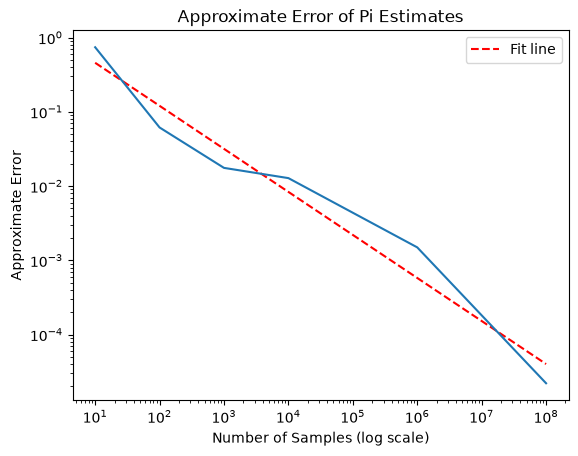

In [17]:
rng = np.random.default_rng(42)
error = []
n_values = [1e1, 1e2, 1e3, 1e4, 1e6, 1e8]
for n in n_values:
    n = int(n)
    pi_estimate, ci = estimate_pi(n, rng)
    approx_error = np.abs(pi_estimate - np.pi)
    error.append(approx_error)

# fit line
m, b = np.polyfit(np.log10(n_values), np.log10(error), 1)
print(f"Fit line: slope = {m}, intercept = {b}")

plt.plot(n_values, 10**(m * np.log10(n_values) + b), linestyle="--", color="red", label="Fit line")
plt.plot(n_values, error)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Samples (log scale)")
plt.ylabel("Approximate Error")
plt.title("Approximate Error of Pi Estimates")
plt.legend()
plt.show()

In [18]:
# Save the Q3 plot for the report
plt.plot(n_values, 10**(m * np.log10(n_values) + b), linestyle="--", color="red", label="Fit line")
plt.plot(n_values, error)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Samples (log scale)")
plt.ylabel("Approximate Error")
plt.title("Approximate Error of Pi Estimates")
plt.legend()
plt.savefig("../figures/iteration3_loglog_error.png", dpi=200)
plt.close()

## 4

In [19]:
# Estimate I = integral of e^x on [0, 1] = e - 1 and compare |I_hat - I| with sigma / sqrt(n),
# sigma^2 = (e^2 - 1)/2 - (e - 1)^2
I = np.e - 1
sigma = np.sqrt((np.e**2 - 1) / 2 - (np.e - 1)**2)
rng_int = np.random.default_rng(42)
for n in [100, 1_000, 10_000]:
    I_hat, s = my_sample_mean(np.exp, n, rng_int)
    print(f"n = {n:>6,}: I_hat = {I_hat:.5f}, |error| = {abs(I_hat - I):.5f}, sigma/sqrt(n) = {sigma / np.sqrt(n):.5f}")

report("quad vs e - 1", integrate.quad(np.exp, 0, 1)[0], I)
U = np.random.default_rng(1).random(1_000)
report("sample mean vs numpy", my_sample_mean(np.exp, 1_000, np.random.default_rng(1)),
       [np.mean(np.exp(U)), np.std(np.exp(U), ddof=1)])

n =    100: I_hat = 1.68773, |error| = 0.03055, sigma/sqrt(n) = 0.04920
n =  1,000: I_hat = 1.72217, |error| = 0.00388, sigma/sqrt(n) = 0.01556
n = 10,000: I_hat = 1.71601, |error| = 0.00227, sigma/sqrt(n) = 0.00492
quad vs e - 1                    max|diff| = 2.22e-16 rel = 1.29e-16
sample mean vs numpy             max|diff| = 0.00e+00 rel = 0.00e+00


## 5

In [20]:
# n Var(I_hat) over R = 2000 runs (from the assignment cell above) against the exact one-sample variances
exact_sm = (np.e**2 - 1) / 2 - (np.e - 1)**2
exact_hm = np.e - 1
n_var_sm = 1000 * sm[:, 0].var()
n_var_hm = 1000 * hm[:, 0].var()
print(f"sample-mean: {n_var_sm:.4f} vs {exact_sm:.4f}, rel. diff = {abs(n_var_sm / exact_sm - 1):.3f}")
print(f"hit-or-miss: {n_var_hm:.4f} vs {exact_hm:.4f}, rel. diff = {abs(n_var_hm / exact_hm - 1):.3f}")
print(f"variance ratio hit-or-miss / sample-mean = {exact_hm / exact_sm:.2f}")

sample-mean: 0.2484 vs 0.2420, rel. diff = 0.026
hit-or-miss: 1.7008 vs 1.7183, rel. diff = 0.010
variance ratio hit-or-miss / sample-mean = 7.10
